In [2]:
# YC1: Load tập dữ liệu ảnh MNIST và chia tập dữ liệu này làm 2 phần: training và testing.
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Load dataset MNIST
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Kích thước X_train ban đầu:", X_train.shape)
print("Kích thước X_test ban đầu :", X_test.shape)
print("Số lượng training samples:", len(X_train))
print("Số lượng testing samples :", len(X_test))

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("\nSau khi reshape:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Kích thước X_train ban đầu: (60000, 28, 28)
Kích thước X_test ban đầu : (10000, 28, 28)
Số lượng training samples: 60000
Số lượng testing samples : 10000

Sau khi reshape:
X_train: (60000, 784)
X_test : (10000, 784)
y_train: (60000, 10)
y_test : (10000, 10)


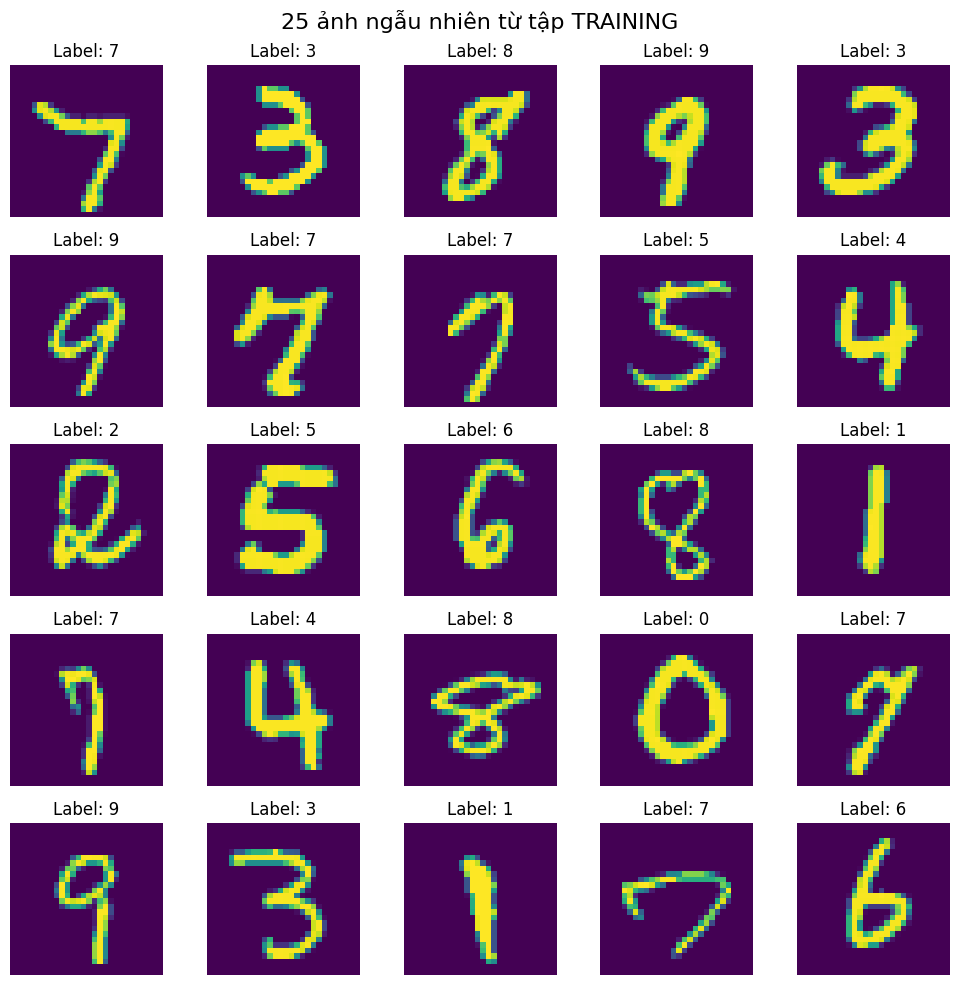

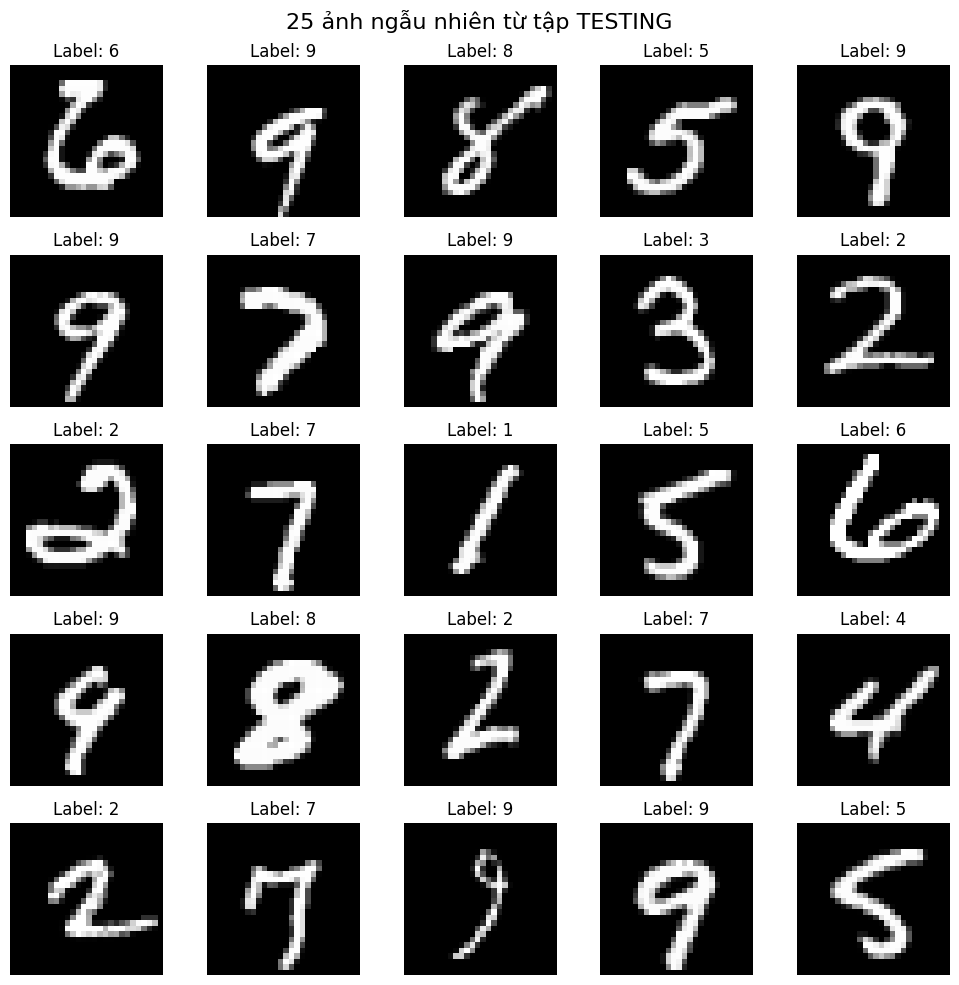

In [3]:
# YC2: Hiển thị 25 ảnh ngẫu nhiên từ tập training (hiển thị ảnh màu) và 25 ảnh ngẫu nhiên từ tập testing (hiển thị ảnh gray).
# Hiển thị với kích thước 5 hàng × 5 cột.
X_train_image = X_train.reshape(-1, 28, 28)
X_test_image = X_test.reshape(-1, 28, 28)

np.random.seed(42)

train_indices = np.random.choice(len(X_train_image), 25, replace=False)
plt.figure(figsize=(10, 10))

for i, index in enumerate(train_indices):
    plt.subplot(5, 5, i + 1)

    # viridis giúp ảnh hiển thị dạng màu
    plt.imshow(X_train_image[index], cmap="viridis")

    # Lấy label từ one-hot
    label = np.argmax(y_train[index])

    plt.title("Label: " + str(label))
    plt.axis("off")

plt.suptitle("25 ảnh ngẫu nhiên từ tập TRAINING", fontsize=16)
plt.tight_layout()
plt.show()

test_indices = np.random.choice(
    len(X_test_image),
    25,
    replace=False
)

plt.figure(figsize=(10, 10))

for i, index in enumerate(test_indices):
    plt.subplot(5, 5, i + 1)

    # grayscale
    plt.imshow(X_test_image[index], cmap="gray")

    label = np.argmax(y_test[index])

    plt.title("Label: " + str(label))
    plt.axis("off")

plt.suptitle("25 ảnh ngẫu nhiên từ tập TESTING", fontsize=16)
plt.tight_layout()
plt.show()

In [4]:
# YC3: Xây dựng mạng nơ-ron gồm 6 lớp ẩn với số Unit lần lượt là 8, 16, 64, 128, 32, 16.
def create_model():

    model = Sequential()

    # Input + Hidden layer 1
    model.add(Dense(8, input_dim=784, activation="relu"))
    # Hidden layer 2
    model.add(Dense(16, activation="relu"))
    # Hidden layer 3
    model.add(Dense(64, activation="relu"))
    # Hidden layer 4
    model.add(Dense(128, activation="relu"))
    # Hidden layer 5
    model.add(Dense(32, activation="relu"))
    # Hidden layer 6
    model.add(Dense(16, activation="relu"))
    # Output layer
    model.add(Dense(10, activation="softmax"))

    return model
# Tạo model
model = create_model()

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Hiển thị cấu trúc model
model.summary()


class PrintLossEvery5Epochs(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        epoch_number = epoch + 1

        if epoch_number % 5 == 0:

            loss = logs.get("loss")
            accuracy = logs.get("accuracy")
            val_loss = logs.get("val_loss")
            val_accuracy = logs.get("val_accuracy")

            print(
                f"Epoch {epoch_number:3d}: "
                f"loss={loss:.4f}, "
                f"accuracy={accuracy:.4f}, "
                f"val_loss={val_loss:.4f}, "
                f"val_accuracy={val_accuracy:.4f}"
            )


class SaveModelEvery5Epochs(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        epoch_number = epoch + 1

        if epoch_number % 5 == 0:

            filename = f"model_epoch_{epoch_number}.keras"

            self.model.save(filename)

            print(f"  -> Đã lưu model: {filename}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │         6,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,658 (80.70 KB)

 Trainable params: 20,658 (80.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch   5: loss=0.0909, accuracy=0.9702, val_loss=0.1721, val_accuracy=0.9555
  -> Đã lưu model: model_epoch_5.keras
Epoch  10: loss=0.0840, accuracy=0.9734, val_loss=0.1883, val_accuracy=0.9518
  -> Đã lưu model: model_epoch_10.keras
Epoch  15: loss=0.0807, accuracy=0.9731, val_loss=0.1987, val_accuracy=0.9532
  -> Đã lưu model: model_epoch_15.keras
Epoch  20: loss=0.0788, accuracy=0.9742, val_loss=0.2120, val_accuracy=0.9552
  -> Đã lưu model: model_epoch_20.keras
Epoch  25: loss=0.0766, accuracy=0.9743, val_loss=0.2179, val_accuracy=0.9513
  -> Đã lưu model: model_epoch_25.keras
Epoch  30: loss=0.0752, accuracy=0.9754, val_loss=0.2433, val_accuracy=0.9517
  -> Đã lưu model: model_epoch_30.keras
Epoch  35: loss=0.0718, accuracy=0.9761, val_loss=0.1902, val_accuracy=0.9593
  -> Đã lưu model: model_epoch_35.keras
Epoch  40: loss=0.0704, accuracy=0.9767, val_loss=0.2425, val_accuracy=0.9560
  -> Đã lưu model: model_epoch_40.keras
Epoch  45: loss=0.0693, accuracy=0.9774, val_loss=0.2346,

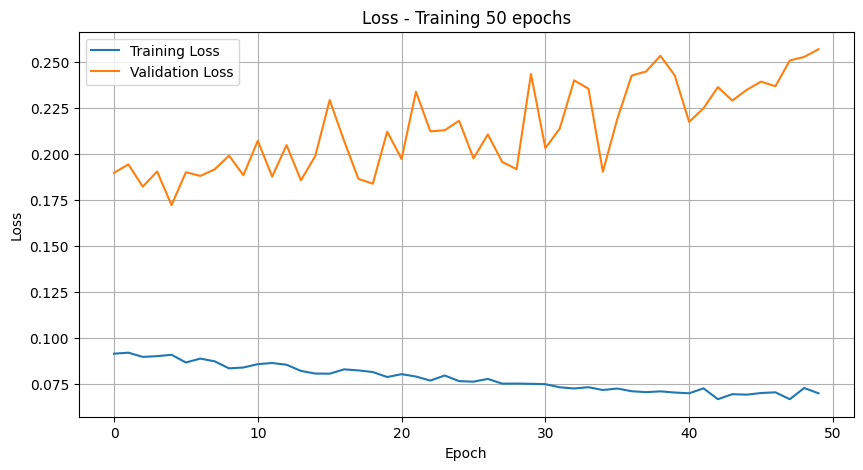

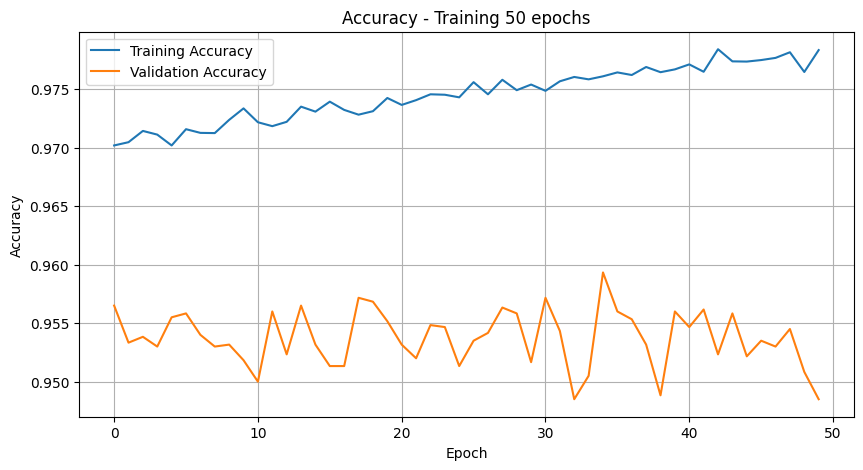

In [ ]:
# YC4: Tiến hành training mạng nơ-ron đã xây dựng trên tập dữ liệu đã được xử lý 50 epochs, 10% làm tập validation,
# batch size = 16 và lưu lại các model. Yêu cầu hiển thị loss sau mỗi 5 epochs.
callbacks_50 = [
    PrintLossEvery5Epochs(),
    SaveModelEvery5Epochs()
]


history_50 = model.fit(X_train, y_train, epochs=50, validation_split=0.1, batch_size=16, callbacks=callbacks_50, verbose=0)

model.save("mnist_model.keras")

plt.figure(figsize=(10, 5))

plt.plot(history_50.history["loss"], label="Training Loss")
plt.plot(history_50.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss - Training 50 epochs")
plt.legend()
plt.grid()

plt.show()


# Accuracy
plt.figure(figsize=(10, 5))

plt.plot(history_50.history["accuracy"], label="Training Accuracy")
plt.plot(history_50.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy - Training 50 epochs")
plt.legend()
plt.grid()

plt.show()

In [6]:
# YC5: Đánh giá model đã được training trên tập testing.
test_loss_50, test_accuracy_50 = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss     :", test_loss_50)
print("Test Accuracy :", test_accuracy_50)
print("Test Accuracy (%):", test_accuracy_50 * 100)

Test Loss     : 0.247160866856575
Test Accuracy : 0.9437000155448914
Test Accuracy (%): 94.37000155448914


In [7]:
# YC6: Huấn luyện lại model 100 epochs và đánh giá lại model đã được training trên tập testing. So sánh kết quả 2 lần huấn luyện.

model_100 = create_model()

model_100.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

callbacks_100 = [PrintLossEvery5Epochs(), SaveModelEvery5Epochs()]

history_100 = model_100.fit(X_train, y_train, epochs=100, validation_split=0.1, batch_size=16, callbacks=callbacks_100, verbose=0)

test_loss_100, test_accuracy_100 = model_100.evaluate(X_test, y_test, verbose=0)

print("Test Loss     :", test_loss_100)
print("Test Accuracy :", test_accuracy_100)
print("Test Accuracy (%):", test_accuracy_100 * 100)

Epoch   5: loss=0.2136, accuracy=0.9356, val_loss=0.1890, val_accuracy=0.9438
  -> Đã lưu model: model_epoch_5.keras
Epoch  10: loss=0.1762, accuracy=0.9464, val_loss=0.1604, val_accuracy=0.9518
  -> Đã lưu model: model_epoch_10.keras
Epoch  15: loss=0.1566, accuracy=0.9513, val_loss=0.1563, val_accuracy=0.9543
  -> Đã lưu model: model_epoch_15.keras
Epoch  20: loss=0.1428, accuracy=0.9543, val_loss=0.1789, val_accuracy=0.9465
  -> Đã lưu model: model_epoch_20.keras
Epoch  25: loss=0.1301, accuracy=0.9583, val_loss=0.1601, val_accuracy=0.9537
  -> Đã lưu model: model_epoch_25.keras
Epoch  30: loss=0.1240, accuracy=0.9592, val_loss=0.1655, val_accuracy=0.9533
  -> Đã lưu model: model_epoch_30.keras
Epoch  35: loss=0.1172, accuracy=0.9616, val_loss=0.1593, val_accuracy=0.9552
  -> Đã lưu model: model_epoch_35.keras
Epoch  40: loss=0.1132, accuracy=0.9627, val_loss=0.1875, val_accuracy=0.9497
  -> Đã lưu model: model_epoch_40.keras
Epoch  45: loss=0.1063, accuracy=0.9650, val_loss=0.1931,